In [1]:
print("Customer Churn Prediction")

Customer Churn Prediction


In [2]:
import pandas as pd
import numpy as np
print("Libraries imported successfully")

Libraries imported successfully


In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [6]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [7]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
print("Total Customers:",len(df))
print("Customers who left:",(df["Churn"]=='Yes').sum())
print("Customers who Stayed:",(df["Churn"]=='No').sum())

Total Customers: 7043
Customers who left: 1869
Customers who Stayed: 5174


In [10]:
df[['tenure','Contract','MonthlyCharges','Churn']].head(10)

,tenure,Contract,MonthlyCharges,Churn
0,1,Month-to-month,29.85,No
1,34,One year,56.95,No
2,2,Month-to-month,53.85,Yes
3,45,One year,42.30,No
4,2,Month-to-month,70.70,Yes
5,8,Month-to-month,99.65,Yes
6,22,Month-to-month,89.10,No
7,10,Month-to-month,29.75,No
8,28,Month-to-month,104.80,Yes
9,62,One year,56.15,No


In [11]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
print("Total Missing Values:",df.isnull().sum().sum())

Total Missing Values: 0


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
churn_percentage = (df["Churn"] == 'Yes').mean() * 100
print('Customer Churn Rate:',round(churn_percentage,2), '%')

Customer Churn Rate: 26.54 %


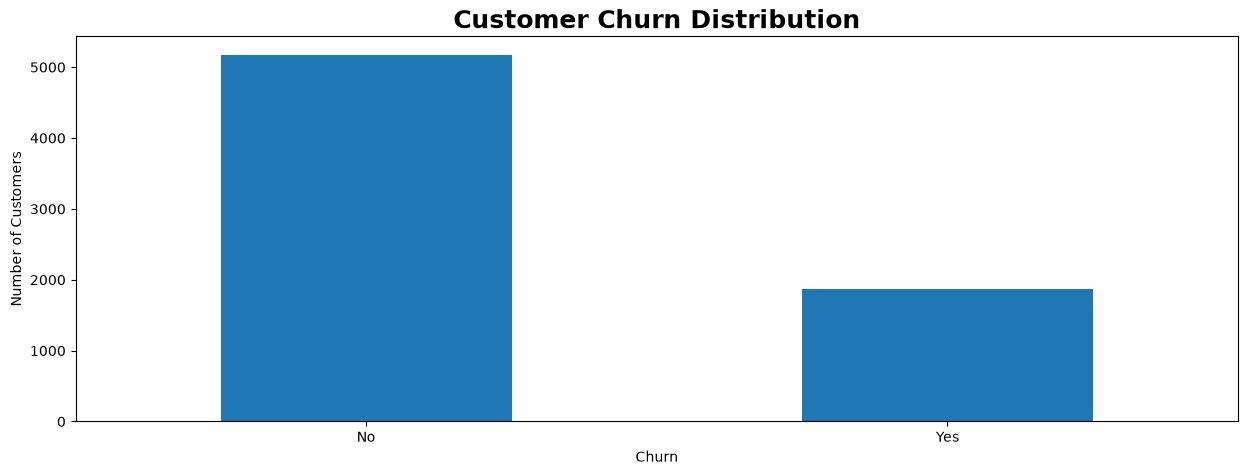

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 5))
df['Churn'].value_counts().plot(kind='bar')
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.title('Customer Churn Distribution',fontweight='bold',fontsize=18)
plt.show()

In [16]:
contract_churn = pd.crosstab(df["Contract"],
                             df["Churn"],
                             normalize="index") * 100
contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


<Figure size 1500x500 with 0 Axes>

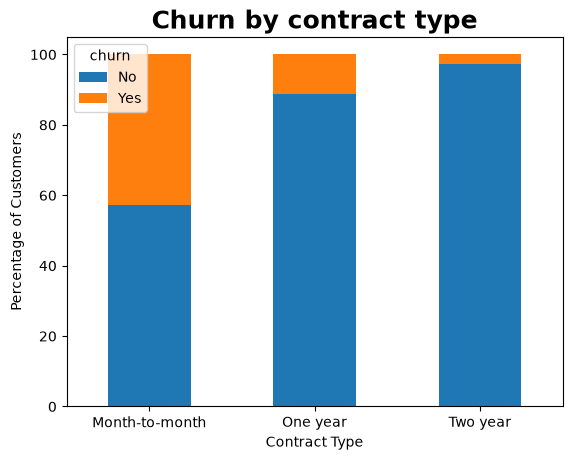

In [17]:
plt.figure(figsize=(15, 5))
contract_churn.plot(kind='bar',
                    stacked=True)
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="churn")
plt.xticks(rotation=0)
plt.title("Churn by contract type",fontweight='bold',fontsize=18)
plt.show()

In [18]:
df.groupby('Churn')["tenure"].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
df=df.drop(columns=["customerID"])
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [21]:
df['Churn'] = df['Churn'].map({'Yes':1,'No':0})
df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [22]:
X = df.drop(columns=['Churn'])
y = df['Churn']
print("No of Features:",X.shape[1])
print("No of Customer Records:",X.shape[0])

No of Features: 19
No of Customer Records: 7043


In [23]:
X = pd.get_dummies(X, drop_first=True,dtype=int)
print("Features after encoding:",X.shape[1])
X.head()

Features after encoding: 6559


,SeniorCitizen,tenure,MonthlyCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,...,TotalCharges_995.35,TotalCharges_996.45,TotalCharges_996.85,TotalCharges_996.95,TotalCharges_997.65,TotalCharges_997.75,TotalCharges_998.1,TotalCharges_999.45,TotalCharges_999.8,TotalCharges_999.9
0,0,1,29.85,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,34,56.95,1,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,2,53.85,1,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,45,42.30,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,2,70.70,0,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [24]:
print("Text columns remaining:",X.select_dtypes(include=['object']).columns.tolist())
print("Missing values in features:",X.isnull().sum().sum())
print("Missing values in target:",y.isnull().sum().sum())

Text columns remaining: []
Missing values in features: 0
Missing values in target: 0


In [25]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training records:",X_train.shape[0])
print("Testing records:",X_test.shape[0])

Training records: 5634
Testing records: 1409


In [26]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training data shape: (5634, 6559)
Testing data shape: (1409, 6559)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

## Machine learning tools imported

In [28]:
model = LogisticRegression(max_iter=1000)

## Model created successfully

In [29]:
model.fit(X_train, y_train)

## Model training completed

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [30]:
y_pred = model.predict(X_test)

print("Predictions completed")
print("First 10 predictions:", y_pred[:10])

Predictions completed
First 10 predictions: [0 1 0 0 0 1 0 0 0 0]


In [31]:
accuracy = accuracy_score(y_test, y_pred)

print("Model accuracy:", round(accuracy * 100, 2), "%")

Model accuracy: 79.42 %


In [32]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))

              precision    recall  f1-score   support

      Stayed       0.84      0.89      0.86      1035
        Left       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



In [33]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[916 119]
 [171 203]]


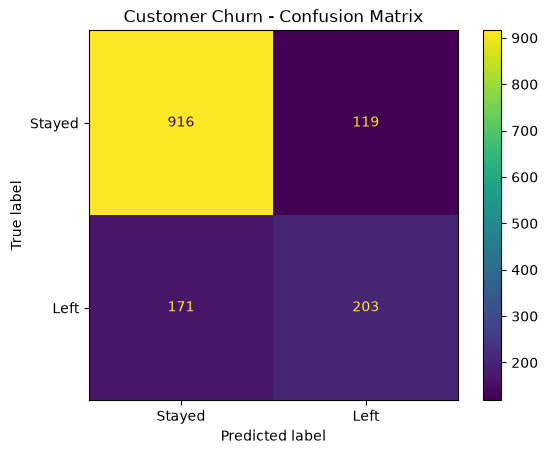

In [34]:

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Left"]
)

plt.title("Customer Churn - Confusion Matrix")
plt.show()

In [35]:
import joblib

joblib.dump(model, "churn_model.pkl")

print("Model saved successfully")

Model saved successfully


In [36]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

print(classification_report(
    y_test, rf_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))

Random Forest Accuracy: 76.79 %
              precision    recall  f1-score   support

      Stayed       0.87      0.81      0.84      1035
        Left       0.55      0.66      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409



In [37]:
print("Logistic Regression:",
      round(accuracy * 100, 2), "%")

print("Random Forest:",
      round(rf_accuracy * 100, 2), "%")

Logistic Regression: 79.42 %
Random Forest: 76.79 %


In [38]:
joblib.dump(rf_model, "random_forest_churn_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [39]:
#pip install streamlit

In [40]:
import os
print(os.listdir())

['.bash_history', '.git', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jdks', '.jssc', '.jupyter', '.lesshst', 'AppData', 'Application Data', 'basics.ipynb', 'churn.ipynb', 'churn_features.pkl', 'churn_model.pkl', 'Conditionals.ipynb', 'Contacts', 'Cookies', 'customers.txt', 'Customer_Churn_Prediction.ipynb', 'Data Visualization.ipynb', 'Documents', 'Downloads', 'Emails.txt', 'Favorites', 'File Handling.ipynb', 'flower.webp', 'Functions.ipynb', 'gray scale img.webp', 'IdeaProjects', 'Linear Regression - Heating load.ipynb', 'Links', 'List Objects .ipynb', 'list.ipynb', 'Local Settings', 'Microsoft', 'ML.ipynb', 'mongodb.practice.txt', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{01277b4e-650e-11ef-891d-9cda3ed3f2fc}.TM.blf', 'NTUSER.DAT{01277b4e-650e-11ef-891d-9cda3ed3f2fc}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{01277b4e-650e-11ef-891d-9cda3ed3f2fc}.TMContainer00000000000000000002.regtrans-ms', 'n

In [41]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nText columns:")
print(df.select_dtypes(include="object").columns.tolist())

Dataset shape: (7043, 20)

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                 int64
dtype: object

Text columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


C:\Users\nooru\AppData\Local\Temp\ipykernel_21108\345840047.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns.tolist())


In [42]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Missing TotalCharges: 11


In [43]:
df = df.dropna(subset=["TotalCharges"]).copy()

print("Dataset shape after cleaning:", df.shape)
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Dataset shape after cleaning: (7032, 20)
Missing TotalCharges: 0


In [44]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Number of features:", X.shape[1])
print("Number of customer records:", X.shape[0])

Number of features: 30
Number of customer records: 7032


In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 5625
Testing records: 1407


In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:",
      round(accuracy * 100, 2), "%")

print(classification_report(
    y_test, y_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))

Logistic Regression Accuracy: 80.31 %
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1033
        Left       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



C:\Users\nooru\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [47]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

print(classification_report(
    y_test, rf_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))

Random Forest Accuracy: 76.83 %
              precision    recall  f1-score   support

      Stayed       0.87      0.80      0.84      1033
        Left       0.55      0.67      0.61       374

    accuracy                           0.77      1407
   macro avg       0.71      0.74      0.72      1407
weighted avg       0.79      0.77      0.77      1407



In [48]:
#import joblib

joblib.dump(rf_model, "random_forest_churn_model.pkl")
joblib.dump(X.columns.tolist(), "churn_features.pkl")

print("Corrected model and features saved successfully!")

Corrected model and features saved successfully!


In [49]:
import joblib

joblib.dump(rf_model, "random_forest_churn_model.pkl")
joblib.dump(X.columns.tolist(), "churn_features.pkl")

print("Both files saved!")

Both files saved!


In [50]:
import os
print(os.getcwd())

C:\Users\nooru


In [51]:
import os
import joblib

folder = r"C:\Users\nooru\Downloads\archive"

joblib.dump(rf_model, os.path.join(folder, "random_forest_churn_model.pkl"))
joblib.dump(X.columns.tolist(), os.path.join(folder, "churn_features.pkl"))

print("Both files saved successfully!")

Both files saved successfully!
